In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Inside0,Inside1,Solution0,Eigenvalues.1,Eigenvectors0.1,Inside0.1,Inside1.1,Solution0.1,Eigenvalues.2,Eigenvectors0.2,Inside0.2,Inside1.2,Solution0.2,Eigenvalues_higher_precision,Eigenvectors_higher_precision0,Inside_higher_precision0,Inside_higher_precision1,Solution_higher_precision0
0,(6.887599402512519+3.7559172106618396e-07j),(-0.0005381027835555163+1.3028315815748803e-05j),-0.51250,-0.82,(6.013438383009324e-05+5.901325197502099e-05j),(7.057402248868916+5.077941065668766e-06j),(-0.0030460186535478783+0.0007319522454531971j),-0.51250,-0.82,(0.0003424053510204146+0.0003359611063656993j),(7.188371279407398+6.375210685582999e-06j),(-0.0014309112133270635+0.004790489450224593j),-0.51250,-0.82,(-0.00014575232885581847+0.0002574188553342246j),(7.057402248868916+5.077941065668766e-06j),(-0.0030460186535478783+0.0007319522454531971j),-0.50225,-0.861,(9.36190603966023e-06+2.4339467189875286e-05j)
1,NaN,(-0.0005105462008323226+0.00024230063895437734j),-0.46125,-0.82,(0.00021597977718233795+0.00021279939166112409j),NaN,(-0.0028302800518086204+0.001977597162260359j),-0.46125,-0.82,(0.0012297776294358546+0.0012110090475889522j),NaN,(0.0002362210083908753+0.005209882491275714j),-0.46125,-0.82,(-0.0004887954283442774+0.0009068170365353788j),(7.188371279407398+6.375210685582999e-06j),(-0.0028302800518086204+0.001977597162260359j),-0.49200,-0.861,(6.20683276192505e-05+6.745639023155977e-05j)
2,NaN,(-0.0005529746588733047+0.0005023891634446778j),-0.41000,-0.82,(0.00030890007547959954+0.00030459055052295636j),NaN,(-0.0029870360589821544+0.0033494565511762425j),-0.41000,-0.82,(0.0017558542214056814+0.001730292230291386j),NaN,(0.002112958693993896+0.005951746148092447j),-0.41000,-0.82,(-0.0006083896167174527+0.0012560618683393923j),(7.18837127940791+6.375212560819077e-06j),(-0.0029870360589821544+0.0033494565511762425j),-0.48175,-0.861,(8.916411402649406e-05+8.33066635507339e-05j)
3,NaN,(-0.0006078445461268076+0.0006550205119923806j),-0.35875,-0.82,(0.00037006881230579574+0.00036487438506532213j),NaN,(-0.0032447850252928017+0.004134711980381915j),-0.35875,-0.82,(0.002096076983319016+0.00206540460465257j),NaN,(0.003199854203463463+0.006505424028394477j),-0.35875,-0.82,(-0.0005838128230377531+0.0014360316750686372j),NaN,(-0.0032447850252928017+0.004134711980381915j),-0.47150,-0.861,(0.00011078110998039882+0.00010210674981166179j)
4,NaN,(-0.0007465947978258453+0.0009108542513743148j),-0.30750,-0.82,(0.00041278232746785187+0.00040702628657214823j),NaN,(-0.003939428269473422+0.005416081806396573j),-0.30750,-0.82,(0.0023251483907358473+0.002291312524322073j),NaN,(0.004986789588660463+0.007603536171800687j),-0.30750,-0.82,(-0.0004582687541302881+0.0015062927005726943j),NaN,(-0.003939428269473422+0.005416081806396573j),-0.46125,-0.861,(0.00012917981677154113+0.0001225052793132281j)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23058,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.46125,0.861,(0.00012917981402739333+0.0001225052798284232j)
23059,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.47150,0.861,(0.00011078110802148922+0.00010210675011861677j)
23060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.48175,0.861,(8.916411285950394e-05+8.330666370945632e-05j)
23061,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.49200,0.861,(6.20683272372349e-05+6.745639031251194e-05j)


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
# Discretization
faces = np.array([105,105])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

#Parameters for the hexagon
n_gon_hexagon = 6
side_length = 1
R = side_length/(2*np.sin(np.pi/n_gon_hexagon))
xm = 0
ym = 0
rot = 0
hexagon = DL.create_polygon(n_gon_hexagon,R,xm,ym,rot,n[0])

# Parameters for the triangle
n_gon_triangle = 3
height = 6/27
R = height*2/3
distance = 11/27
angles = np.linspace(0,2*np.pi, n_gon_hexagon, endpoint=False)

xm = distance*np.cos(angles)
ym = distance*np.sin(angles)

rot1 = 2*np.pi/3
rot2 = 2*np.pi/(3*2)
hexagon_triangles = np.empty(n_gon_hexagon+1, dtype=object)
hexagon_triangles[0] = hexagon

# Create 6 triangles at the correct positions
for i in range(n_gon_hexagon):
    if np.mod(i,2) == 0:
        triangle_temp = DL.create_polygon(n_gon_triangle,R,xm[i],ym[i],rot1,n[1])
    else:
        triangle_temp = DL.create_polygon(n_gon_triangle,R,xm[i],ym[i],rot2,n[1])
    tringle_flip = np.flip(triangle_temp,1)
    hexagon_triangles[i+1] = tringle_flip

# Stack all the boundaries together
vi = np.copy(hexagon_triangles)
collocation_nodes = np.empty(n_gon_hexagon+1, dtype= object)
for i in range(n_gon_hexagon+1):
    collocation_nodes[i] = DL.create_collocation_nodes(vi[i],alpha) 

In [7]:
vi_with_end_point = np.copy(vi)
for i in range(n_gon_hexagon+1):
    vi_with_end_point[i] = np.append(vi_with_end_point[i],vi[i][:,:1],axis = 1)

(np.float64(-1.1000000000000003),
 np.float64(1.1000000000000003),
 np.float64(-0.9526279441628832),
 np.float64(0.9526279441628829))

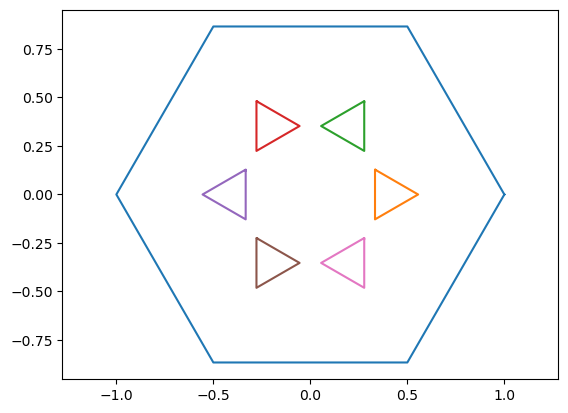

In [8]:
for i in range(n_gon_hexagon+1):
    plt.plot(vi_with_end_point[i][0,:], vi_with_end_point[i][1,:])
plt.axis('equal')

In [9]:
def ray_tracing_in_holes(boundary, xmid, ymid):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    x_start : float
        Start value of a square in x-direction.
    x_end : float
        End value of a square in x-direction.
    x_steps : int
        Number of points in x-direction that should be checked to be inside the given domain without holes.
    y_start : float
        Start value of a square in y-direction.
    y_end : float
        End value of a square in y-direction.
    y_steps : int
        Number of points in y-direction that should be checked to be inside the given domain without holes.

    Returns
    -------
    xy_inside : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [10]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'(6.887599402512519+3.7559172106618396e-07j)'

In [15]:
6.887599402512519 * 6.887599402512519

47.43902552949081

In [12]:
eigenvalues = inside_solution['Eigenvalues.1'][0]
eigenvalues

'(7.057402248868916+5.077941065668766e-06j)'

In [13]:
7.057402248868916*7.057402248868916

49.80692650234004

In [ ]:
eigenvalues = inside_solution['Eigenvalues_higher_precision'][0]
eigenvalues

In [ ]:
xy_inside = inside_solution[['Inside_higher_precision0', 'Inside_higher_precision1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T
xy_inside

In [ ]:
sol = inside_solution['Solution_higher_precision0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)
sol

In [ ]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([vi_with_end_point[0]]), xmid, ymid)
mask2 = ray_tracing_in_holes(np.array([vi_with_end_point[1]]), xmid, ymid)
mask3 = ray_tracing_in_holes(np.array([vi_with_end_point[2]]), xmid, ymid)
mask4 = ray_tracing_in_holes(np.array([vi_with_end_point[3]]), xmid, ymid)
mask5 = ray_tracing_in_holes(np.array([vi_with_end_point[4]]), xmid, ymid)
mask6 = ray_tracing_in_holes(np.array([vi_with_end_point[5]]), xmid, ymid)
mask7 = ray_tracing_in_holes(np.array([vi_with_end_point[6]]), xmid, ymid)


mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7

triang.set_mask(mask)
# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=20)

plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1)


for i in range(n_gon_hexagon+1):
    plt.plot(vi_with_end_point[i][0,:],vi_with_end_point[i][1,:], 'black')
    
plt.axis('square')
plt.xlim(-1.05,1.05)
plt.ylim(-1.05,1.05)
plt.savefig('hexagon_six_triangles_11_24.eps', format="eps")
plt.show()

In [16]:
eigenvalues = inside_solution['Eigenvalues.2'][0]
eigenvalues

'(7.188371279407398+6.375210685582999e-06j)'

In [17]:
7.188371279407398 * 7.188371279407398

51.67268165060915